# Assignment 1: Exploratory Data Analysis and Baselines
**CENG313 · NFL Big Data Bowl 2026 – Prediction (Kaggle)**

**Task.** When the quarterback throws the ball, predict the `(x, y)` position of selected players for every
frame (10 Hz) until the ball arrives. We are given each player's tracking data *before* the throw, the
targeted receiver and the ball landing location.

**Metric.** $\mathrm{RMSE}=\sqrt{\frac{1}{2N}\sum_i\left[(x_i-\hat x_i)^2+(y_i-\hat y_i)^2\right]}$ (yards).

**Contents**
1. Setup (Colab / local)
2. Data overview and quality checks
3. Play-level analysis: time in the air, pass depth, ball landing spots
4. Player-level analysis: roles, kinematics at the throw
5. Post-pass movement: how players actually move while the ball is in the air
6. Coordinate normalization and feature tables
7. Baselines (4 physics rules, 2 fitted physics rules, 2 learned residual models) with game-grouped 5-fold CV
8. Error analysis and conclusions

All reusable code lives in `src/` (`data.py`, `models.py`, `utils.py`); this notebook only calls it.

## 1. Setup
In **Google Colab** the cell below clones the repository and downloads the competition data with the Kaggle
API (upload your `kaggle.json` when prompted and accept the competition rules on Kaggle first).
Locally, place the data in `./data/nfl-big-data-bowl-2026-prediction/` or set `NFL_DATA_DIR`.

In [1]:
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/akifkorkmaz11/GROUP63_CENG313.git"
REPO_DIR = "GROUP63_CENG313"

if IN_COLAB:
    if not os.path.exists(REPO_DIR):
        subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
    data_root = "data/nfl-big-data-bowl-2026-prediction"
    if not os.path.isdir(os.path.join(data_root, "train")):
        from google.colab import files
        if not os.path.exists(os.path.expanduser("~/.kaggle/kaggle.json")):
            print("Upload kaggle.json (Kaggle > Settings > API > Create New Token)")
            files.upload()
            os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
            os.replace("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
            os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
        subprocess.run(["kaggle", "competitions", "download", "-c", "nfl-big-data-bowl-2026-prediction", "-p", "data"], check=True)
        subprocess.run(["unzip", "-q", "-o", "data/nfl-big-data-bowl-2026-prediction.zip", "-d", data_root], check=True)

sys.path.insert(0, os.getcwd())

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from src import data as D, models as M, utils as U

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.grid": True, "grid.alpha": 0.25})
ROLE_COLORS = {"Targeted Receiver": "#e76f51", "Defensive Coverage": "#2d6a4f",
               "Other Route Runner": "#f4a261", "Passer": "#8d99ae"}
FIG_DIR = "reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)
def save(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")

DATA_DIR = D.find_data_dir()
print("Data directory:", DATA_DIR)

Data directory: /home/claude/data/nfl-big-data-bowl-2026-prediction


## 2. Data overview and quality checks
The training data covers the 18 weeks of the 2023 regular season. Each week has an **input** file (all 22
players, every frame *before* the throw) and an **output** file (only the players we must predict, every
frame *after* the throw – these are the targets).

In [3]:
with U.timer("load"):
    inp, out = D.load_train(DATA_DIR)
print(f"input : {inp.shape[0]:>10,} rows x {inp.shape[1]} cols  ({inp.memory_usage(deep=True).sum()/1e9:.2f} GB in memory)")
print(f"output: {out.shape[0]:>10,} rows x {out.shape[1]} cols")
inp.head(3).T

[load] 8.5s
input :  4,880,579 rows x 24 cols  (1.15 GB in memory)
output:    562,936 rows x 7 cols


,0,1,2
game_id,2023090700,2023090700,2023090700
play_id,101,101,101
player_to_predict,False,False,False
nfl_id,54527,54527,54527
frame_id,1,2,3
play_direction,right,right,right
absolute_yardline_number,42,42,42
player_name,Bryan Cook,Bryan Cook,Bryan Cook
player_height,6-1,6-1,6-1
player_weight,210,210,210


In [4]:
summary = pd.DataFrame({
    "games": [inp.game_id.nunique()],
    "plays": [inp[D.PLAY_KEYS].drop_duplicates().shape[0]],
    "players (unique)": [inp.nfl_id.nunique()],
    "player-plays to predict": [out[D.PLAYER_KEYS].drop_duplicates().shape[0]],
    "frames to predict (rows)": [len(out)],
}).T.rename(columns={0: "count"})
summary

,count
games,272
plays,14108
players (unique),1384
player-plays to predict,46045
frames to predict (rows),562936


In [5]:
# Missing values, and value ranges of the main tracking columns
quality = pd.DataFrame({
    "missing": inp.isna().sum(),
    "dtype": inp.dtypes.astype(str),
})
print(quality[quality.missing > 0] if (quality.missing > 0).any() else "No missing values in the input files.")
print("Missing values in output:", int(out.isna().sum().sum()))
inp[["x", "y", "s", "a", "dir", "o", "num_frames_output", "ball_land_x", "ball_land_y"]].describe().T.round(2)

No missing values in the input files.
Missing values in output: 0


,count,mean,std,min,25%,50%,75%,max
x,4880579.0,60.50,23.49,0.41,42.63,60.41,78.23,119.86
y,4880579.0,26.81,10.01,0.62,18.99,26.85,34.62,52.88
s,4880579.0,3.02,2.23,0.00,1.09,2.72,4.62,12.53
a,4880579.0,2.12,1.42,0.00,1.01,1.92,3.04,17.12
dir,4880579.0,180.50,100.72,0.00,90.91,179.56,270.83,360.00
o,4880579.0,181.54,98.01,0.00,91.74,180.14,271.58,360.00
num_frames_output,4880579.0,11.64,5.33,5.00,8.00,10.00,14.00,94.00
ball_land_x,4880579.0,60.52,25.30,-5.26,42.61,60.51,78.47,125.85
ball_land_y,4880579.0,26.64,15.44,-3.91,13.30,26.47,39.87,57.33


**Observations**
* No missing values. `x`, `y` stay within the 120 × 53.3 yard field; `ball_land_y` can be slightly outside
  the field (throwaways towards the sideline).
* Speeds reach ~11 yd/s (≈ 37 km/h) which is realistic for NFL players.

**Consistency checks.** (a) Every output player must appear in the input with `player_to_predict = True`;
(b) the first output frame should continue smoothly from the last input frame.

In [6]:
to_pred = inp.loc[inp.player_to_predict.astype(bool), D.PLAYER_KEYS].drop_duplicates()
out_players = out[D.PLAYER_KEYS].drop_duplicates()
missing = out_players.merge(to_pred, how="left", indicator=True).query("_merge == 'left_only'")
print(f"(a) output players not flagged in input: {len(missing)}  |  flagged but not in output: "
      f"{len(to_pred) - len(out_players) + len(missing)}")

last_in = inp.sort_values("frame_id").groupby(D.PLAYER_KEYS, observed=True).tail(1)
first_out = out[out.frame_id == 1]
gap = first_out.merge(last_in[D.PLAYER_KEYS + ["x", "y", "s"]], on=D.PLAYER_KEYS, suffixes=("", "_last"))
gap["jump"] = np.hypot(gap.x - gap.x_last, gap.y - gap.y_last)
gap["expected"] = gap.s * D.DT
print("(b) distance between last input frame and first output frame (yards):")
print(gap[["jump", "expected"]].describe().round(3).T)

(a) output players not flagged in input: 0  |  flagged but not in output: 0
(b) distance between last input frame and first output frame (yards):
            count   mean    std  min    25%    50%    75%    max
jump      46045.0  0.459  0.202  0.0  0.309  0.453  0.610  1.044
expected  46045.0  0.455  0.200  0.0  0.306  0.449  0.604  1.034


Output frame 1 is exactly one frame (0.1 s) after the last input frame: the median jump matches
`speed × 0.1 s`. So the post-pass trajectory continues the pre-pass one without a time gap.

## 3. Play-level analysis

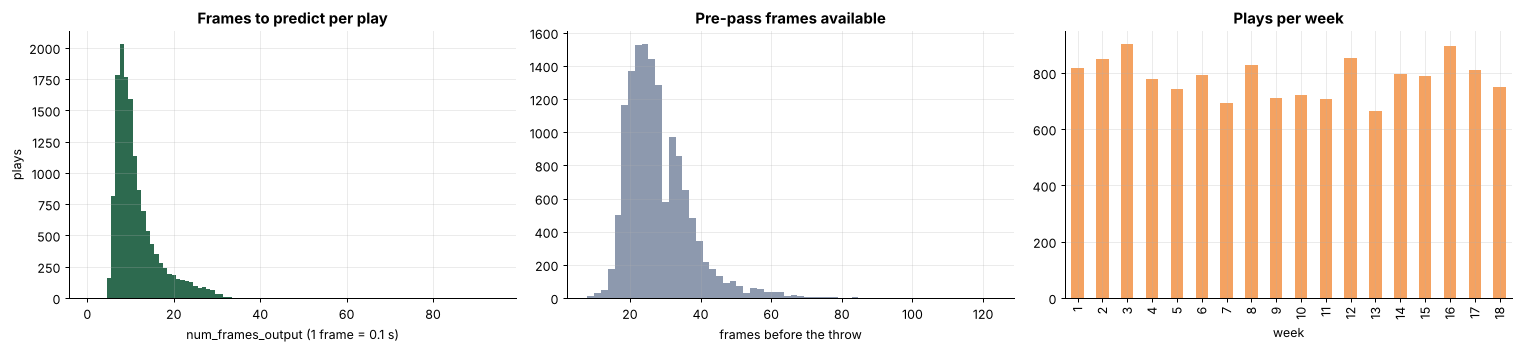

,count,mean,std,min,25%,50%,75%,max
num_frames_output,14108.0,11.37,5.15,5.00,8.00,10.00,13.00,94.00
air_time_s,14108.0,1.14,0.51,0.50,0.80,1.00,1.30,9.40
pre_pass_frames,14108.0,28.13,9.26,8.00,22.00,26.00,32.00,123.00
pass_depth,14105.0,8.41,9.72,-11.75,2.17,5.38,12.78,62.29
pass_length,14105.0,21.53,10.05,0.71,14.23,18.95,26.35,67.28


In [7]:
plays = inp.drop_duplicates(D.PLAY_KEYS)[D.PLAY_KEYS + ["week", "play_direction", "absolute_yardline_number",
                                                        "num_frames_output", "ball_land_x", "ball_land_y"]].copy()
pre_frames = inp.groupby(D.PLAY_KEYS, observed=True).frame_id.max().rename("pre_pass_frames")
plays = plays.merge(pre_frames.reset_index(), on=D.PLAY_KEYS)
qb = D.normalize_direction(inp[(inp.player_role == "Passer")]).sort_values("frame_id").groupby(D.PLAY_KEYS, observed=True).tail(1)
plays = plays.merge(qb[D.PLAY_KEYS + ["x", "y", "los_x", "ball_land_x", "ball_land_y"]].rename(
    columns={"x": "qb_x", "y": "qb_y", "ball_land_x": "bx", "ball_land_y": "by"}), on=D.PLAY_KEYS, how="left")
plays["air_time_s"] = plays.num_frames_output * D.DT
plays["pass_depth"] = plays.bx - plays.los_x          # yards past the line of scrimmage
plays["pass_length"] = np.hypot(plays.bx - plays.qb_x, plays.by - plays.qb_y)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].hist(plays.num_frames_output, bins=np.arange(0.5, plays.num_frames_output.max() + 1.5), color="#2d6a4f")
ax[0].set(title="Frames to predict per play", xlabel="num_frames_output (1 frame = 0.1 s)", ylabel="plays")
ax[1].hist(plays.pre_pass_frames, bins=60, color="#8d99ae")
ax[1].set(title="Pre-pass frames available", xlabel="frames before the throw")
plays.groupby("week").size().plot.bar(ax=ax[2], color="#f4a261")
ax[2].set(title="Plays per week", xlabel="week")
plt.tight_layout(); save(fig, "01_play_overview"); plt.show()
plays[["num_frames_output", "air_time_s", "pre_pass_frames", "pass_depth", "pass_length"]].describe().T.round(2)

Play direction balance:
 play_direction
right    0.504
left     0.496
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
corr(pass length, air time) = 0.948


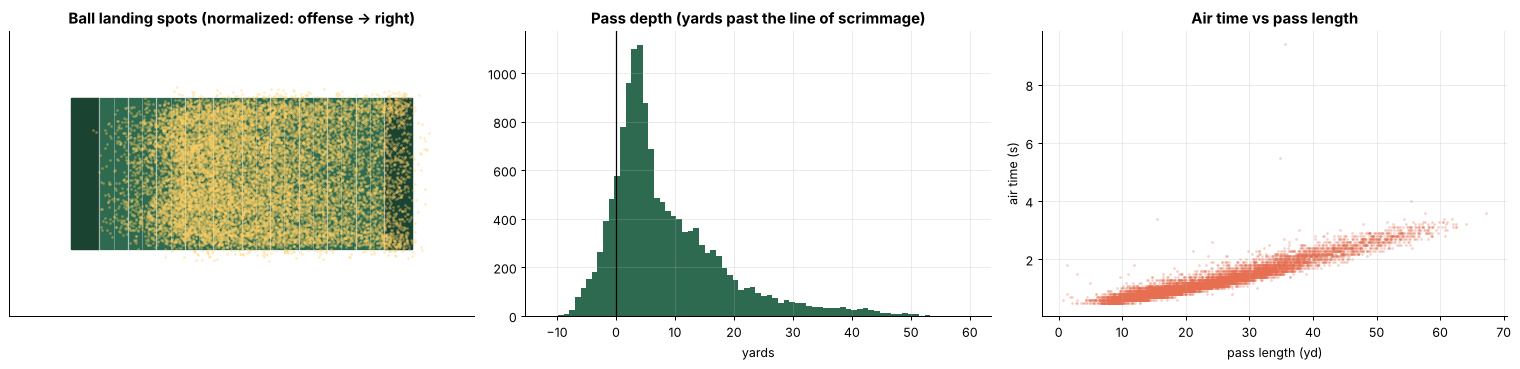

In [8]:
print("Play direction balance:\n", plays.play_direction.value_counts(normalize=True).round(3).to_string())
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
U.draw_field(ax[0])
ax[0].scatter(plays.bx, plays.by, s=2, alpha=0.25, color="#ffd166")
ax[0].set_title("Ball landing spots (normalized: offense → right)")
ax[1].hist(plays.pass_depth.clip(-15, 60), bins=75, color="#2d6a4f")
ax[1].axvline(0, color="k", lw=1)
ax[1].set(title="Pass depth (yards past the line of scrimmage)", xlabel="yards")
ax[2].scatter(plays.pass_length, plays.air_time_s, s=2, alpha=0.2, color="#e76f51")
ax[2].set(title="Air time vs pass length", xlabel="pass length (yd)", ylabel="air time (s)")
plt.tight_layout(); save(fig, "02_ball_landing"); plt.show()
print("corr(pass length, air time) =", round(plays[["pass_length", "air_time_s"]].corr().iloc[0, 1], 3))

**Observations**
* The ball is in the air for **1.0 s on median** (10 frames, 75% of plays ≤ 1.3 s) with a long, rare tail up
  to 9.4 s. Since the error of any predictor grows with time, these long plays will weigh heavily in the RMSE.
* Most passes are short: the median landing spot is 5.4 yards past the line of scrimmage and a quarter of passes
  go beyond 12.8 yards. Air time is almost linear in pass length (correlation 0.95), so `num_frames_output` is
  effectively a proxy for pass length.
* Plays are roughly balanced between left and right, so normalizing the direction doubles the useful
  examples for each situation.

## 4. Player-level analysis

player_to_predict   False  True 
player_role                     
Defensive Coverage  62356  31937
Other Route Runner  50644      0
Passer              14105      0
Targeted Receiver       0  14108


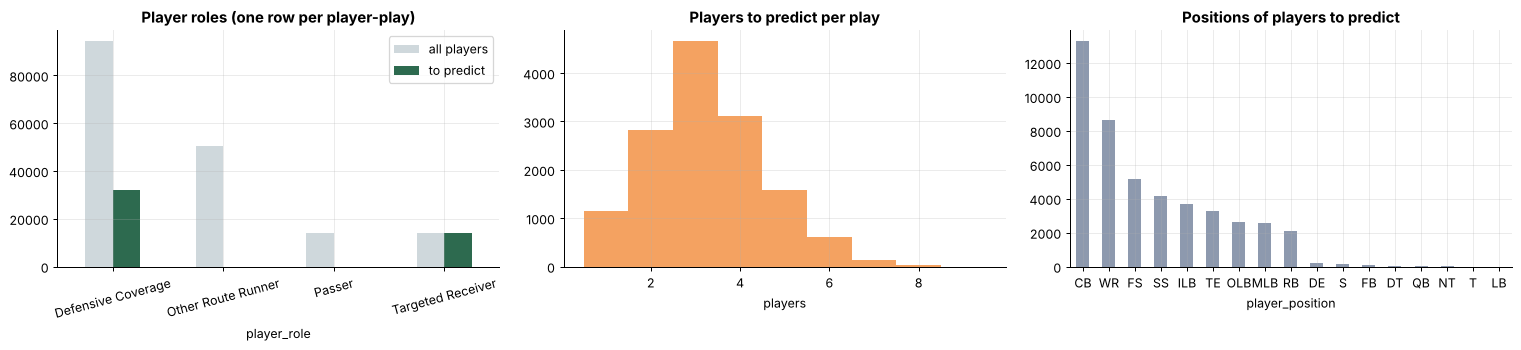

In [9]:
pp = inp.drop_duplicates(D.PLAYER_KEYS)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
pred_roles = pp[pp.player_to_predict.astype(bool)].player_role.astype(str).value_counts()
all_roles = pp.player_role.astype(str).value_counts()
pd.DataFrame({"all players": all_roles, "to predict": pred_roles}).fillna(0).plot.bar(ax=ax[0], color=["#cfd8dc", "#2d6a4f"], rot=15)
ax[0].set_title("Player roles (one row per player-play)")
n_pred = pp[pp.player_to_predict.astype(bool)].groupby(D.PLAY_KEYS, observed=True).size()
ax[1].hist(n_pred, bins=np.arange(0.5, n_pred.max() + 1.5), color="#f4a261")
ax[1].set(title="Players to predict per play", xlabel="players")
pos = pp[pp.player_to_predict.astype(bool)].player_position.astype(str).value_counts()
pos.plot.bar(ax=ax[2], color="#8d99ae", rot=0)
ax[2].set_title("Positions of players to predict")
plt.tight_layout(); save(fig, "03_roles"); plt.show()
print(pd.crosstab(pp.player_role.astype(str), pp.player_to_predict.astype(bool)))

* The players to predict are the **targeted receiver** (always exactly one per play) plus about **one third of
  the defenders in coverage** (31,937 of 94,293), presumably those involved in the play; the passer and other
  route runners are never predicted. Typically 3 players are predicted per play (mean 3.3).
* Defenders make up 69% of the players to predict (cornerbacks are the most common position). A good model
  must capture how defenders react to the ball, not only how the receiver runs.

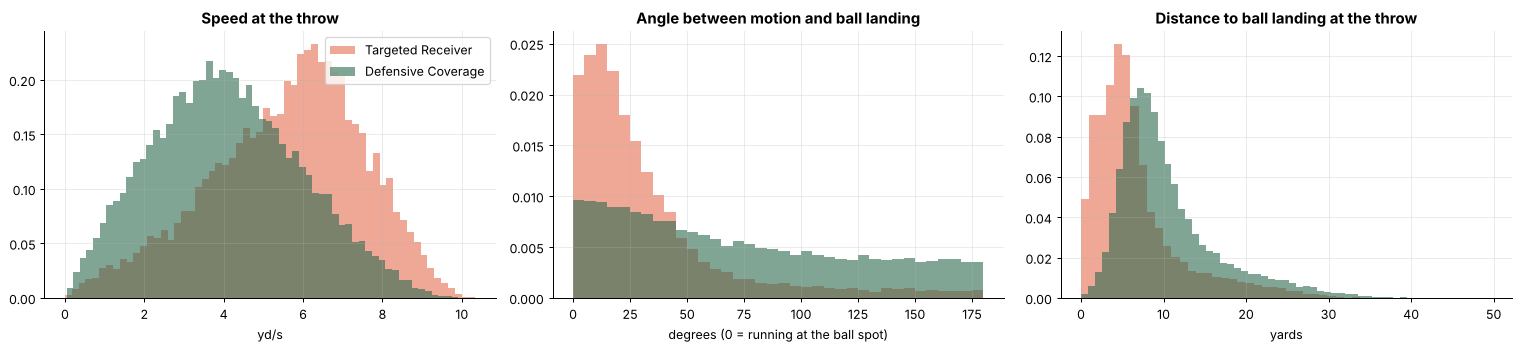

,s,a,dir_vs_ball,dist_ball
player_role,,,,
Defensive Coverage,4.0,2.52,61.900002,8.92
Targeted Receiver,5.8,2.97,21.920000,5.30


In [10]:
lastf = D.add_kinematics(D.normalize_direction(inp[inp.player_to_predict.astype(bool)]))
lastf = lastf.groupby(D.PLAYER_KEYS, observed=True).tail(1).copy()
lastf["angle_to_ball"] = np.rad2deg(np.arctan2(lastf.ball_land_x - lastf.x, lastf.ball_land_y - lastf.y)) % 360
lastf["dir_vs_ball"] = D.angle_diff(lastf.dir, lastf.angle_to_ball)
lastf["dist_ball"] = np.hypot(lastf.ball_land_x - lastf.x, lastf.ball_land_y - lastf.y)
roles = ["Targeted Receiver", "Defensive Coverage"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for r in roles:
    d = lastf[lastf.player_role.astype(str) == r]
    ax[0].hist(d.s, bins=60, alpha=0.6, density=True, label=r, color=ROLE_COLORS[r])
    ax[1].hist(d.dir_vs_ball, bins=36, alpha=0.6, density=True, label=r, color=ROLE_COLORS[r])
    ax[2].hist(d.dist_ball.clip(0, 50), bins=50, alpha=0.6, density=True, label=r, color=ROLE_COLORS[r])
ax[0].set(title="Speed at the throw", xlabel="yd/s"); ax[0].legend()
ax[1].set(title="Angle between motion and ball landing", xlabel="degrees (0 = running at the ball spot)")
ax[2].set(title="Distance to ball landing at the throw", xlabel="yards")
plt.tight_layout(); save(fig, "04_kinematics_at_throw"); plt.show()
lastf.groupby(lastf.player_role.astype(str))[["s", "a", "dir_vs_ball", "dist_ball"]].median().round(2)

* At the throw, targeted receivers are **faster** than defenders and already move roughly towards the
  landing spot (small angle), while defenders' directions are spread out: many are still back-pedalling or
  moving with their assignment.
* Targeted receivers start much closer to the landing spot than most defenders.

## 5. How do players move while the ball is in the air?
We join the targets with the last pre-pass state and measure (i) how far players travel and (ii) how much
their path deviates from simply continuing at constant velocity.

[feature table] 3.6s
training rows: 562,936  |  columns: 65
Targeted receiver distance to the landing spot: median 5.3 yd at the throw -> 1.2 yd when the ball arrives


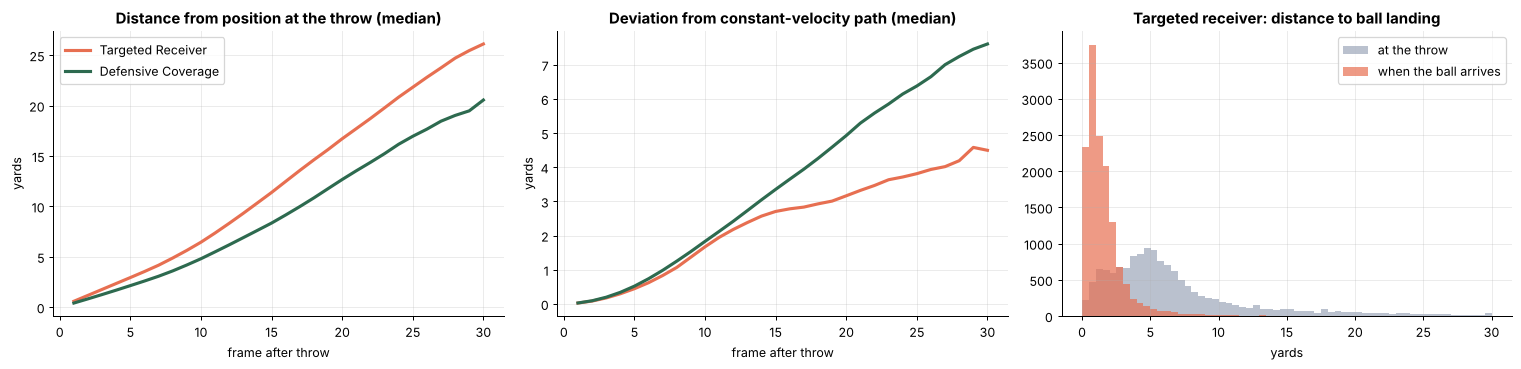

In [11]:
with U.timer("feature table"):
    rows = D.build_training_frame(inp, out)
rows["role"] = rows.player_role.astype(str)
rows["disp"] = np.hypot(rows.x_true - rows.x, rows.y_true - rows.y)
rows["cv_err"] = np.hypot(rows.x_true - rows.x - rows.cv_dx, rows.y_true - rows.y - rows.cv_dy)
print(f"training rows: {len(rows):,}  |  columns: {rows.shape[1]}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for r in roles:
    g = rows[rows.role == r].groupby("frame_id")
    ax[0].plot(g.disp.median().index[:30], g.disp.median().values[:30], color=ROLE_COLORS[r], lw=2.5, label=r)
    ax[1].plot(g.cv_err.median().index[:30], g.cv_err.median().values[:30], color=ROLE_COLORS[r], lw=2.5, label=r)
ax[0].set(title="Distance from position at the throw (median)", xlabel="frame after throw", ylabel="yards"); ax[0].legend()
ax[1].set(title="Deviation from constant-velocity path (median)", xlabel="frame after throw", ylabel="yards")
tr_end = rows[(rows.role == "Targeted Receiver") & (rows.frame_id == rows.num_frames_output)]
d0 = np.hypot(tr_end.ball_land_x - tr_end.x, tr_end.ball_land_y - tr_end.y)
d1 = np.hypot(tr_end.ball_land_x - tr_end.x_true, tr_end.ball_land_y - tr_end.y_true)
ax[2].hist(d0.clip(0, 30), bins=60, alpha=0.6, label="at the throw", color="#8d99ae")
ax[2].hist(d1.clip(0, 30), bins=60, alpha=0.7, label="when the ball arrives", color="#e76f51")
ax[2].set(title="Targeted receiver: distance to ball landing", xlabel="yards"); ax[2].legend()
plt.tight_layout(); save(fig, "05_post_pass_motion"); plt.show()
print(f"Targeted receiver distance to the landing spot: median {d0.median():.1f} yd at the throw -> "
      f"{d1.median():.1f} yd when the ball arrives")

**Key findings for modelling**
* Players move a lot – the targeted receiver ~6 yards in a 1-second flight and ~17 yards in 2 s – so the
  "last position" predictor will be poor.
* The constant-velocity path is accurate for the first ~5 frames, then its error grows steadily with time.
  **Defenders deviate more than receivers**: the receiver is already running his route towards the ball,
  while defenders change direction when they react to the throw.
* The targeted receiver ends up very close to the landing spot (median ~1–2 yd). The ball landing location
  is therefore the most important piece of information, especially late in the flight.

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


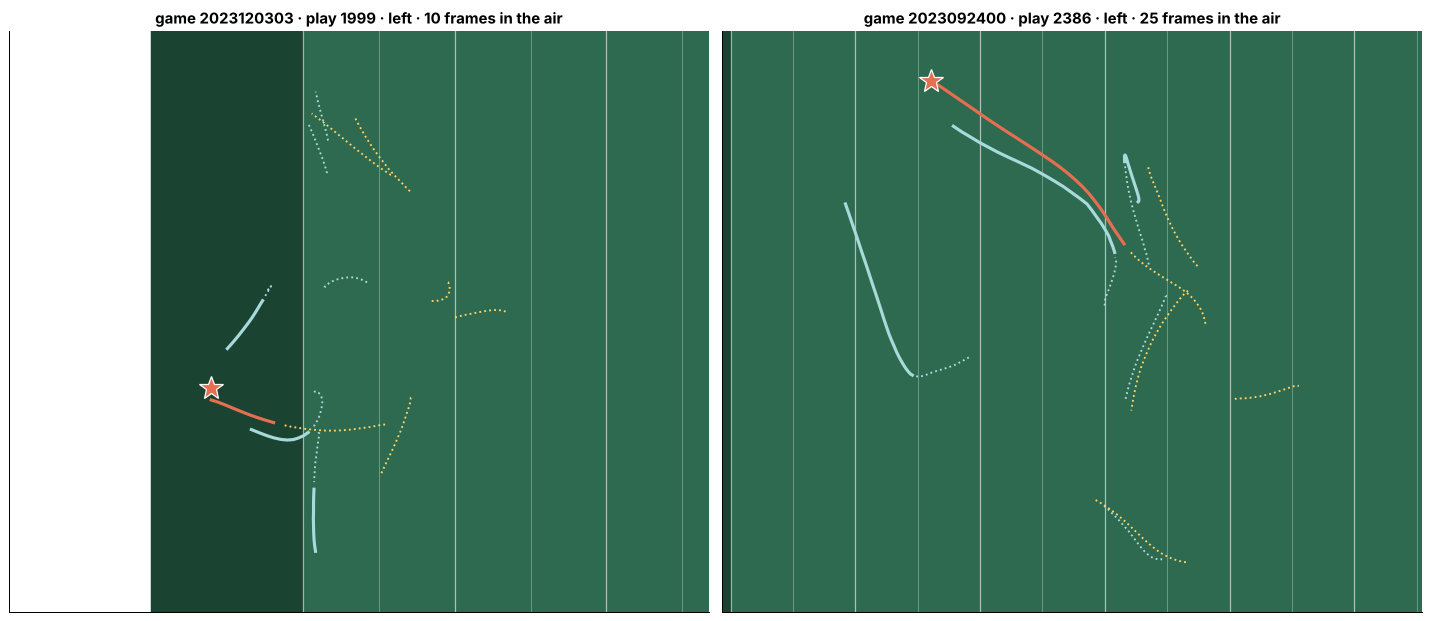

In [12]:
examples = rows.groupby(D.PLAY_KEYS).num_frames_output.first().sort_values()
picks = [examples.index[len(examples) // 2], examples.index[int(len(examples) * 0.97)]]
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for a, (g, p) in zip(ax, picks):
    U.plot_play(inp, out, g, p, ax=a)
plt.tight_layout(); save(fig, "06_example_plays"); plt.show()

*Dotted*: movement before the throw. *Solid*: true movement after the throw (orange = targeted receiver).
*Star*: ball landing spot. Left: a typical short pass; right: a long pass where the receiver and defenders
converge on the landing spot.

## 6. Coordinate normalization and feature tables
* **Normalization.** Plays where the offense moves left are rotated by 180°: `x → 120 − x`, `y → 53.3 − y`,
  `dir, o → dir + 180°`. After this the offense always moves towards increasing x. Predictions are rotated back.
  (Check above: quarterbacks stand ~5 yards *behind* the normalized line of scrimmage, as expected.)
* **Velocity.** NGS angles start at +y and grow clockwise, so `vx = s·sin(dir)`, `vy = s·cos(dir)`.
* **Feature table.** One row per (player, output frame) with the last pre-pass state and simple features:
  kinematics, ball landing geometry, player attributes and time (`frame_id`, `t`, fraction of flight).
  *Interaction features between players (nearest opponent, coverage pairs …) are deliberately left for
  Assignment 2.*

In [13]:
print(len(D.FEATURES), "features:", ", ".join(D.FEATURES))
qb_check = D.normalize_direction(inp[(inp.frame_id == 1) & (inp.player_role == "Passer")])
print(f"Check: median QB position relative to the normalized line of scrimmage = {(qb_check.x - qb_check.los_x).median():.1f} yd")
cx = rows[D.FEATURES].corrwith(rows.x_true - rows.x - rows.cv_dx).abs()
cy = rows[D.FEATURES].corrwith(rows.y_true - rows.y - rows.cv_dy).abs()
corr = pd.DataFrame({"|corr| with x-residual": cx, "|corr| with y-residual": cy}).round(3)
corr.loc[corr.max(axis=1).sort_values(ascending=False).index[:12]]

42 features: x, y, s, a, dir, o, vx, vy, vx_pos, vy_pos, ax_est, ay_est, s_change5, dir_change5, flight_time, num_frames_output, ball_land_x, ball_land_y, dx_ball, dy_ball, dist_ball, angle_to_ball, dir_vs_ball, o_vs_ball, req_speed, closing_speed, height_in, player_weight, age, role_id, pos_id, is_offense, x_from_los, dist_sideline, frame_id, t, t_frac, frames_left, cv_dx, cv_dy, ball_dx_lin, ball_dy_lin
Check: median QB position relative to the normalized line of scrimmage = -4.9 yd


,|corr| with x-residual,|corr| with y-residual
ball_dy_lin,0.007,0.565
ay_est,0.010,0.463
dy_ball,0.006,0.455
ball_dx_lin,0.425,0.019
ax_est,0.423,0.004
dx_ball,0.356,0.014
dist_ball,0.258,0.010
ball_land_y,0.001,0.236
s_change5,0.228,0.004
req_speed,0.202,0.006


The residual of the constant-velocity prediction (what is left to learn) is most correlated with the
straight-line path to the ball (`ball_dx_lin`, `ball_dy_lin`) and with the recent acceleration
(`ax_est`, `ay_est`): players keep turning the way they were already turning, and they turn towards the ball.

## 7. Baselines
| # | Baseline | Idea | Trained? |
|---|---|---|---|
| B0 | Last position | Player stops | no |
| B1 | Constant velocity | Keep speed and direction | no |
| B2 | Constant acceleration | Use the acceleration vector from the last frames | no |
| B3 | Damped velocity | Velocity decays as e^(−kt); k fitted | 1 parameter |
| B4 | Straight to ball | Run straight to the landing spot, arriving with the ball | no |
| B5 | Role-aware physics blend | Per role and flight phase, blend B3 and B4 with a fitted weight | 10 weights + k |
| B6 | Ridge residual | Linear model of the B1 residual (features and features × t) | linear model |
| B7 | GBDT residual | Gradient-boosted trees (scikit-learn) on the B1 residual | tree ensemble |

**Validation.** 5-fold `GroupKFold` by `game_id`: all plays of a game are either in training or in
validation. The hidden test set contains unseen games, so random splits would leak information (same
players, weather, play-calling) and overestimate performance. Untrained baselines get the same folds so the
numbers are directly comparable.

In [14]:
results, oof = [], {}
for cls in M.ALL_BASELINES:
    print(cls.name)
    r = U.group_kfold_oof(cls, rows, n_splits=5, verbose=cls.trainable)
    oof[cls.name] = (r["x"], r["y"])
    results.append({"baseline": cls.name, "trained": cls.trainable, "OOF RMSE": r["rmse"],
                    "fold mean": np.mean(r["folds"]), "fold std": np.std(r["folds"]), "seconds": r["seconds"]})
    print(f"  -> OOF RMSE {r['rmse']:.4f}  ({r['seconds']:.0f}s)")
res = pd.DataFrame(results).set_index("baseline")
res["vs constant velocity"] = (1 - res["OOF RMSE"] / res.loc["Constant velocity", "OOF RMSE"]).map("{:+.1%}".format)
os.makedirs("results", exist_ok=True)
res.round(4).to_csv("results/assignment1_baselines.csv")
res.round(4)

Last position
  -> OOF RMSE 4.2437  (1s)
Constant velocity
  -> OOF RMSE 1.6401  (1s)
Constant acceleration
  -> OOF RMSE 1.8174  (1s)
Damped velocity
  fold 0: 1.7039
  fold 1: 1.6141
  fold 2: 1.7448
  fold 3: 1.5927
  fold 4: 1.6419
  -> OOF RMSE 1.6607  (3s)
Straight to ball
  -> OOF RMSE 3.9219  (1s)
Role-aware physics blend
  fold 0: 1.2775
  fold 1: 1.2169
  fold 2: 1.3521
  fold 3: 1.1814
  fold 4: 1.2426
  -> OOF RMSE 1.2557  (3s)
Ridge residual
  fold 0: 0.8955
  fold 1: 0.8204
  fold 2: 1.1591
  fold 3: 0.8017
  fold 4: 0.8508
  -> OOF RMSE 0.9153  (7s)
GBDT residual
  fold 0: 0.7376
  fold 1: 0.6697
  fold 2: 0.9029
  fold 3: 0.6642
  fold 4: 0.6830
  -> OOF RMSE 0.7372  (136s)


,trained,OOF RMSE,fold mean,fold std,seconds,vs constant velocity
baseline,,,,,,
Last position,False,4.2437,4.2429,0.0684,0.6680,-158.7%
Constant velocity,False,1.6401,1.6385,0.0670,0.6600,+0.0%
Constant acceleration,False,1.8174,1.8065,0.1905,0.6660,-10.8%
Damped velocity,True,1.6607,1.6595,0.0567,2.6012,-1.3%
Straight to ball,False,3.9219,3.9217,0.0493,0.6223,-139.1%
Role-aware physics blend,True,1.2557,1.2541,0.0582,2.7460,+23.4%
Ridge residual,True,0.9153,0.9055,0.1307,7.3360,+44.2%
GBDT residual,True,0.7372,0.7315,0.0896,136.4738,+55.0%


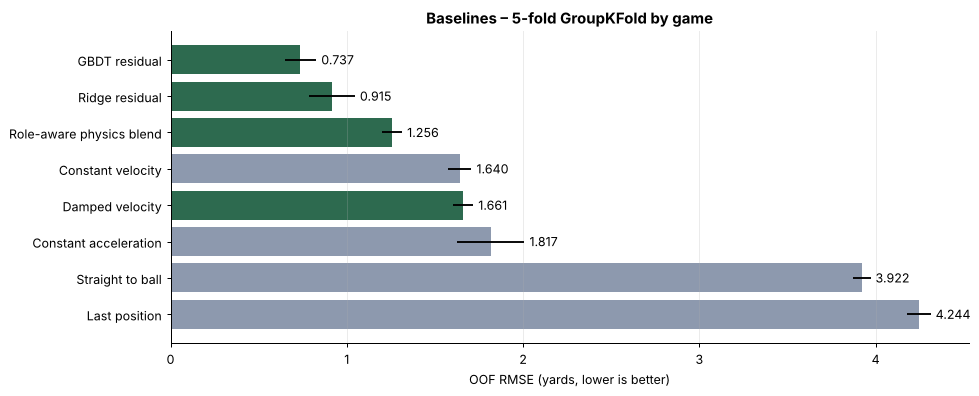

In [15]:
fig, ax = plt.subplots(figsize=(11, 4.5))
order = res["OOF RMSE"].sort_values(ascending=False)
colors = ["#2d6a4f" if res.loc[n, "trained"] else "#8d99ae" for n in order.index]
bars = ax.barh(order.index, order.values, xerr=res.loc[order.index, "fold std"], color=colors)
ax.bar_label(bars, fmt="%.3f", padding=4)
ax.set(xlabel="OOF RMSE (yards, lower is better)", title="Baselines – 5-fold GroupKFold by game")
ax.grid(axis="y", visible=False)
plt.tight_layout(); save(fig, "07_baseline_rmse"); plt.show()

## 8. Error analysis

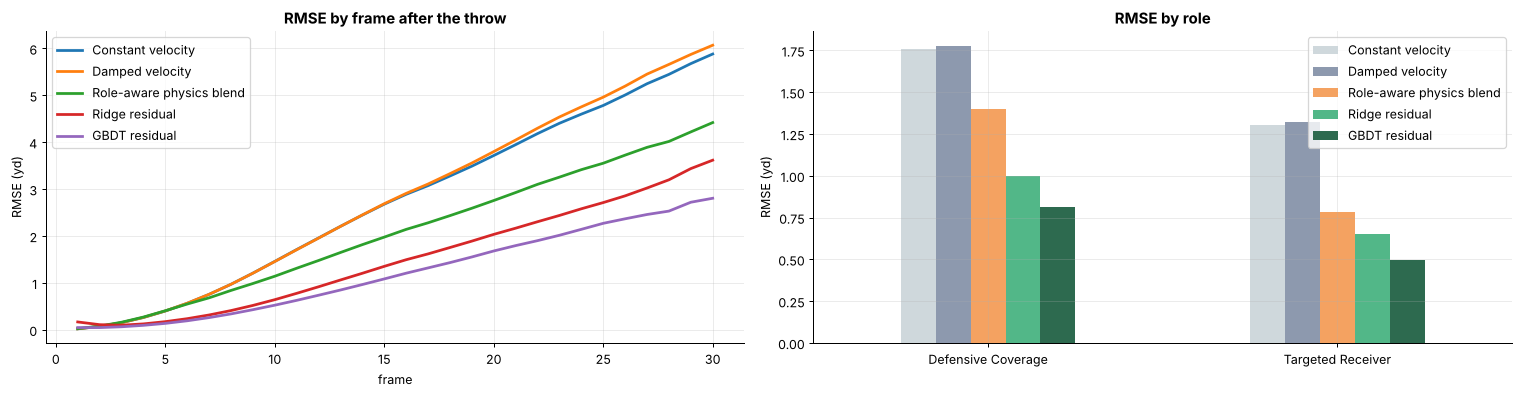

,Constant velocity,Damped velocity,Role-aware physics blend,Ridge residual,GBDT residual
role,,,,,
Defensive Coverage,1.756,1.778,1.399,1.001,0.813
Targeted Receiver,1.305,1.323,0.786,0.651,0.499


In [16]:
show = ["Constant velocity", "Damped velocity", "Role-aware physics blend", "Ridge residual", "GBDT residual"]
fig, ax = plt.subplots(1, 2, figsize=(17, 4.5))
for name in show:
    px, py = oof[name]
    by_f = U.rmse_by(rows, px, py, "frame_id")
    ax[0].plot(by_f.index[:30], by_f.values[:30], lw=2.2, label=name)
ax[0].set(title="RMSE by frame after the throw", xlabel="frame", ylabel="RMSE (yd)"); ax[0].legend()
by_role = pd.DataFrame({n: U.rmse_by(rows, *oof[n], "role") for n in show})
by_role.plot.bar(ax=ax[1], rot=0, color=["#cfd8dc", "#8d99ae", "#f4a261", "#52b788", "#2d6a4f"])
ax[1].set(title="RMSE by role", ylabel="RMSE (yd)", xlabel="")
plt.tight_layout(); save(fig, "08_error_by_frame_role"); plt.show()
by_role.round(3)

In [17]:
rows["air_bucket"] = pd.cut(rows.num_frames_output, [0, 10, 15, 20, 30, 100], labels=["≤1.0s", "1.0–1.5s", "1.5–2.0s", "2.0–3.0s", ">3.0s"])
share = rows.groupby("air_bucket", observed=True).size() / len(rows)
tbl = pd.DataFrame({n: U.rmse_by(rows, *oof[n], "air_bucket") for n in ["Constant velocity", "Role-aware physics blend", "GBDT residual"]})
tbl.insert(0, "share of rows", share.map("{:.1%}".format))
px, py = oof["GBDT residual"]
se = ((rows.x_true - px) ** 2 + (rows.y_true - py) ** 2) / 2
tbl["share of GBDT squared error"] = (se.groupby(rows.air_bucket, observed=True).sum() / se.sum()).map("{:.1%}".format)
tbl.round(3)

,share of rows,Constant velocity,Role-aware physics blend,GBDT residual,share of GBDT squared error
air_bucket,,,,,
≤1.0s,33.8%,0.606,0.559,0.213,2.8%
1.0–1.5s,30.3%,1.223,0.912,0.429,10.2%
1.5–2.0s,16.2%,1.855,1.350,0.740,16.3%
2.0–3.0s,17.9%,2.597,1.966,1.188,46.5%
>3.0s,1.8%,4.359,3.558,2.677,24.1%


Passes in the air longer than 2 s are only ~20% of the rows but produce ~70% of the GBDT's squared error.
Improving long passes is therefore the main lever for the metric.

Other observations from the table and plots:
* **Constant acceleration is worse than constant velocity**: acceleration estimated from a few noisy frames
  explodes when extrapolated quadratically over 1–3 s.
* **Damped velocity does not help** (fitted k ≈ 0.05/s): players do not slow down uniformly; deceleration
  depends on the role and on where the ball goes.
* **Straight to ball is poor for everyone except late frames of the targeted receiver** – defenders do not
  run to the ball spot – but blending it per role (B5) gains 23% over constant velocity.
* The learned residual models reduce the error for both roles, and defenders remain the hardest (0.81 vs 0.50 yd).

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


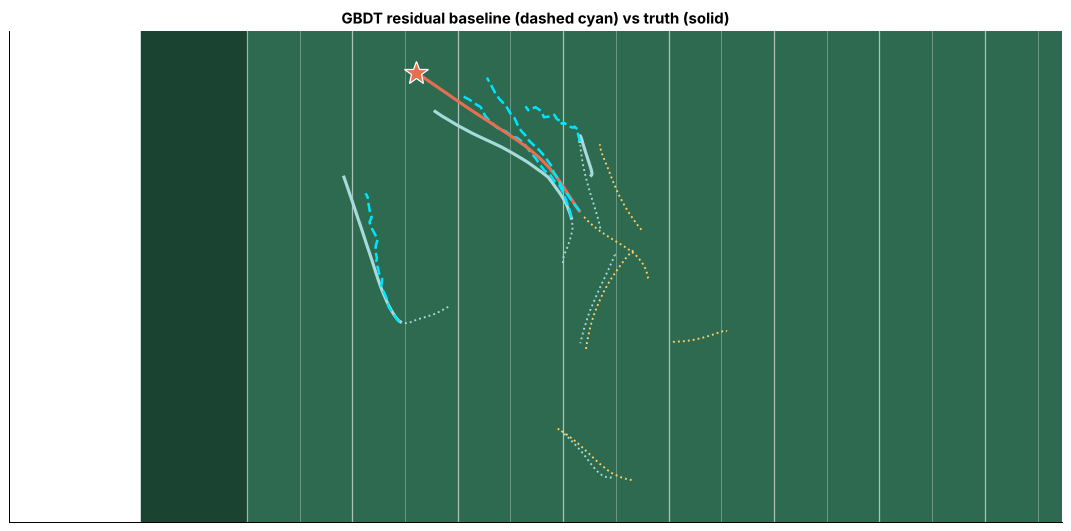

In [18]:
# Predictions of the best baseline on a long pass (rotated back to original coordinates)
g, p = picks[1]
sel = rows[(rows.game_id == g) & (rows.play_id == p)]
px, py = oof["GBDT residual"]
ox, oy = D.flip_xy(px[sel.index], py[sel.index], sel.is_left.to_numpy())
pred_df = pd.DataFrame({"nfl_id": sel.nfl_id.to_numpy(), "x": ox, "y": oy})
fig, ax = plt.subplots(figsize=(12, 6))
U.plot_play(inp, out, g, p, preds=pred_df, ax=ax, title="GBDT residual baseline (dashed cyan) vs truth (solid)")
plt.tight_layout(); save(fig, "09_example_prediction"); plt.show()

### Sanity check on the public test files
`test.csv` lists the rows to predict and `test_input.csv` holds their pre-pass data (2024 season games). We
train the best baseline on all training data and check that we can produce one prediction per test row in
the original coordinate system. (Official scoring runs through Kaggle's evaluation API in a Kaggle notebook.)

In [19]:
test, test_input = D.load_test(DATA_DIR)
best = M.GBDTResidual().fit(rows)
t_rows = D.expand_to_frames(D.build_player_table(test_input), frames=test)
tx, ty = best.predict(t_rows)
tx, ty = D.flip_xy(tx, ty, t_rows.is_left.to_numpy())
sub = pd.DataFrame({"id": test["id"], "x": tx, "y": ty})
assert len(sub) == len(test) and sub[["x", "y"]].notna().all().all()
sub.to_csv("results/test_predictions_gbdt_baseline.csv", index=False)
print(sub.shape); sub.head()

(5837, 3)


,id,x,y
0,12350,88.392455,34.370298
1,12351,88.658207,34.388302
2,12352,88.944563,34.472940
3,12353,89.360899,34.680035
4,12354,89.746448,34.772270


## 9. Conclusions and plan for Assignment 2
**What we learned from the EDA**
* The task is dominated by **time**: errors are tiny for the first frames and grow quickly; long passes
  (> 2 s) carry a large share of the total squared error.
* The **ball landing spot** is the strongest signal: the targeted receiver ends up 1–2 yards from it, and
  defenders converge on it late in the play.
* Roles behave differently: receivers bend towards the ball, defenders react later and partially.

**Baselines**
* Pure physics (constant velocity) gives 1.64 yd; adding role-dependent attraction towards the ball spot
  with 10 fitted weights already improves it by 23% (1.26 yd).
* Learned corrections on top of constant velocity reach 0.92 yd (ridge) and **0.74 yd (GBDT, −55%)**.
  This is the baseline to beat in Assignment 2. Fold-to-fold variation (±0.09) shows that game-level splits
  matter: some games are much harder than others.

**Plan for the proposed solution (Assignment 2)**
1. Interaction features: nearest opponent / teammate, defender–receiver pairing, players near the landing spot.
2. Data augmentation by mirroring the field across its long axis (`y → 53.3 − y`).
3. Sequence models (GRU / Transformer over the last frames of all players) that output whole trajectories.
   The GBDT baseline predicts every frame independently, so its paths zig-zag (see the example above);
   a trajectory-level model or smoothing should fix this.
4. Tuned LightGBM / ensembling, and a Kaggle late submission through the evaluation API.